# 06 Mining delay propagation and cascades (SIMULATED medium scenario)

**Everything here is SIMULATED.** The mining uses **observable data only** (scheduled and actual times, delays, train types, the timetable graphs, the weather state). It never reads `delay_attribution` or the ground-truth cascades; those are used only in `07_mining_validation.ipynb`.

**Freeze rule.** Every threshold and design choice was set on the **decision window 2024-01-01 .. 2024-10-31** and written to `configs/mining_frozen.yaml` (slack fractions, gap window G, rake turnaround limit, number of communities). The frozen method is then applied unchanged to the rest of the training window, **2024-11-01 .. 2025-08-31** (the "application window"). Validation fold 2 (Sep-Oct 2025) and the test window are never loaded.

Results below are shown for the application window (out of design) with the decision window next to it where useful. Whether a finding may be an artifact of the simulator design (trains run daily, one lane per direction, flat 5-8% slack, random freight, headway) is discussed in `reports/phase5_findings.md`.

In [1]:
import os, sys, json, warnings
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
from src.analysis import mining_pipeline as mp, eda, patterns as pt, criticality as cr, communities as cm, cascades as cs
from src.analysis.calibrate import load_frozen

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
BLUE, ORANGE, GREEN, GREY, RED = "#1f6f9f", "#d98c1f", "#6a9f58", "#888888", "#b5483a"
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"mining_{name}.png", dpi=130, bbox_inches="tight"); plt.show()
S = "  [SIMULATED]"
DEC = ("2024-01-01", "2024-10-31"); APP = ("2024-11-01", "2025-08-31")
dec, app = mp.load_saved(*DEC), mp.load_saved(*APP)
prm = load_frozen()
print("frozen parameters:", {k: v for k, v in prm.__dict__.items() if k != "slack_fraction"})
print("slack fractions (estimated from observable data):", dict(prm.slack_fraction))
nodes = app["nodes"]; names = nodes.node_name.tolist(); km = nodes.set_index("node").km_from_new_delhi
lab = lambda s: f"{names[s]}-{names[s + 1]}"
print("decision window cascades:", len(dec["cascades"]), "| application window cascades:", len(app["cascades"]))

frozen parameters: {'G': 6.0, 'L_late': 5.0, 'A_link': 2.0, 'P': 15.0, 'T_entry': 15.0, 'R_min': 5.0, 'G_rake': 180.0}
slack fractions (estimated from observable data): {'Duronto': 0.05, 'Mail/Express': 0.07, 'Passenger': 0.08, 'Rajdhani': 0.05, 'Shatabdi': 0.06, 'Superfast': 0.06, '_halt': 0.5, 'other': 0.06}
decision window cascades: 12221 | application window cascades: 12518


## 1. Primary vs secondary delay

For every section passage (a train crossing a section, counted from arrival at the entry station to arrival at the exit station) the delay is split into **inherited** (carried from upstream and still there), **absorbed** (recovered with slack: running slack plus shortened halts) and **added** (generated in this section, which includes waiting at the entry station for a leading train). The slack is not in a timetable, so it is estimated from late, uncontested trains in clear weather; the estimates are printed above. A **primary event** is a passage adding at least 15 minutes that no late leading train explains (a leader that entered at most 6 minutes earlier, is at least 5 minutes late and exits within 6 minutes before it).

application window: 4,558,521 passages; per passage mean inherited 11.10 min, added 0.46 min, absorbed by slack 0.25 min
added minutes explained by a late leader: 40.2% (passages linked to a leader, added >= 2 min)
primary events: 8697 | per day 28.6


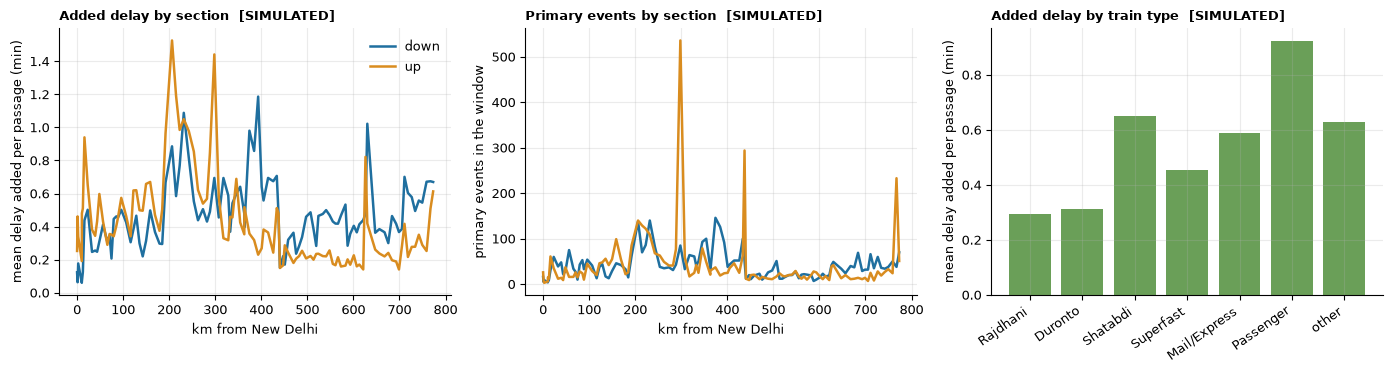

              passages  mean_added  mean_inherited  mean_absorbed  share_adding_2plus
type                                                                                 
Rajdhani        646595       0.295           8.436          0.130               0.039
Duronto         248898       0.311           8.735          0.116               0.036
Shatabdi         72959       0.650          16.806          0.179               0.085
Superfast      2492332       0.454          11.708          0.254               0.052
Mail/Express   1003865       0.587          10.869          0.354               0.063
Passenger        45600       0.923           6.960          0.685               0.091
other            48272       0.629          27.281          0.277               0.066

sections generating the most added delay (minutes in the window):
 section  dir  passages  mean_added  total_added_min  share_adding_2plus
 TDL-HNG   -1     27322        1.53     41697.269531                0.17
 ETW-EKL   -1

In [2]:
ab = app["added_by_section"]; at = app["added_by_type"]
tot_pass = ab.passages.sum()
inh, add, absb = (ab.passages * ab.mean_inherited).sum(), ab.total_added_min.clip(lower=0).sum(), (ab.passages * ab.mean_absorbed).sum()
print(f"application window: {tot_pass:,.0f} passages; per passage mean inherited {inh / tot_pass:.2f} min, added {ab.total_added_min.sum() / tot_pass:.2f} min, absorbed by slack {absb / tot_pass:.2f} min")
print(f"added minutes explained by a late leader: {app['passage_links'].added.sum() / ab.total_added_min.clip(lower=0).sum():.1%} (passages linked to a leader, added >= 2 min)")
print("primary events:", len(app["primary_events"]), "| per day %.1f" % (len(app["primary_events"]) / ((pd.Timestamp(APP[1]) - pd.Timestamp(APP[0])).days + 1)))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for dr, c, l in ((1, BLUE, "down"), (-1, ORANGE, "up")):
    s = ab[ab.dir == dr].sort_values("sec")
    axes[0].plot(km[s.sec].values, s.mean_added, color=c, lw=1.8, label=l)
    pe = app["primary_events"][app["primary_events"].dir == dr].groupby("sec").size().reindex(s.sec).fillna(0)
    axes[1].plot(km[s.sec].values, pe.values, color=c, lw=1.8, label=l)
axes[0].set_xlabel("km from New Delhi"); axes[0].set_ylabel("mean delay added per passage (min)"); axes[0].legend(frameon=False)
axes[0].set_title("Added delay by section" + S, loc="left", fontweight="bold", fontsize=9)
axes[1].set_xlabel("km from New Delhi"); axes[1].set_ylabel("primary events in the window")
axes[1].set_title("Primary events by section" + S, loc="left", fontweight="bold", fontsize=9)
order = ["Rajdhani", "Duronto", "Shatabdi", "Superfast", "Mail/Express", "Passenger", "other"]
t = at.set_index("type").reindex(order)
axes[2].bar(range(len(order)), t.mean_added, color=GREEN); axes[2].set_xticks(range(len(order))); axes[2].set_xticklabels(order, rotation=35, ha="right")
axes[2].set_ylabel("mean delay added per passage (min)"); axes[2].set_title("Added delay by train type" + S, loc="left", fontweight="bold", fontsize=9)
plt.tight_layout(); save(fig, "01_decomposition")
print(t[["passages", "mean_added", "mean_inherited", "mean_absorbed", "share_adding_2plus"]].round(3).to_string())
top = ab.assign(section=ab.sec.map(lab)).sort_values("total_added_min", ascending=False).head(8)[["section", "dir", "passages", "mean_added", "total_added_min", "share_adding_2plus"]]
print("\nsections generating the most added delay (minutes in the window):"); print(top.round(2).to_string(index=False))
pe = app["primary_events"]
pw = (pd.Timestamp("2025-01-01") + pd.to_timedelta(pe.t_in, unit="m")).dt.normalize()
from src import splits as _sp
_wx = pd.concat([pd.read_parquet(Path(s.dir) / "weather.parquet") for s in _sp.sources("medium")]); _wx["date"] = pd.to_datetime(_wx.date)
_wx = _wx[(_wx.date >= APP[0]) & (_wx.date <= APP[1])].set_index("date").state.astype(str)
pw = pw.map(_wx)
print("\nprimary events by train type:", pe.type.value_counts().to_dict())
print("primary events per day by weather:", (pw.value_counts() / _wx.value_counts()).round(1).to_dict(), "| share on fog days %.3f (fog days are %.3f of the window)" % ((pw == "fog").mean(), (_wx == "fog").mean()))

## 2. Contagion between trains, per section and direction

Pairs are taken from the **timetable** (a train and its scheduled predecessor within 6 minutes), not from what happened. Per section and direction: (a) the linear coefficient of the follower's added delay on the leader's delay at entry (with the controls described in `src/analysis/contagion.py`, robust 95% interval), and (b) the **pass-on ratio**: follower delay minutes caused per minute of leader delay, over all late leaders and over primary events (bootstrap interval, label absorb / amplify / uncertain). The linear coefficient is reported as specified; it is close to zero because most late leaders are followed by trains that are already late in the same platoon, so delay moves between trains in a small share of cases (mainly around primary events).

linear coefficient beta (follower added delay per minute of leader delay): median 0.0035, 95th percentile 0.030, max 0.111
sections where the 95% interval excludes zero on the positive side: 119 of 214; labels (absorb/amplify/uncertain on beta*m): {'absorb': 214}
pass-on ratio: A_all median 0.012; A_primary (sections with >= 30 primary events) median 0.34 (range 0.05-0.58), n sections 103
pass-on labels: {'uncertain': 111, 'absorb': 103}
share of added delay that a late leader explains (rho): median 0.49, range 0.12-0.73


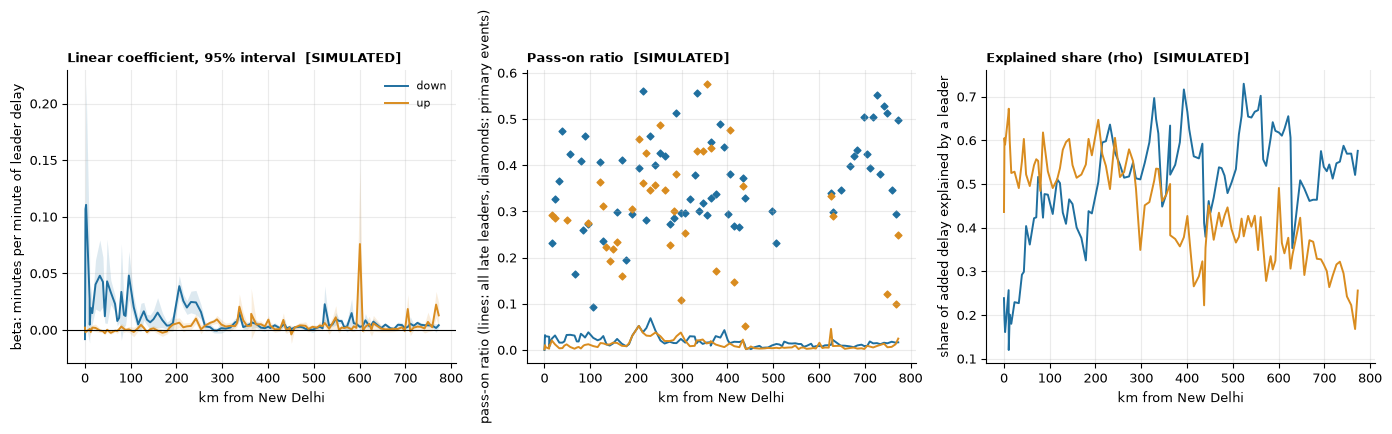

 section  dir  n_primary  A_primary  A_primary_lo  A_primary_hi  rho label_pass_on
 PHD-KNS   -1         49       0.58          0.44          0.71 0.47        absorb
 HNG-FZD    1         70       0.56          0.45          0.66 0.60        absorb
GHSR-ULD    1         41       0.56          0.39          0.69 0.65        absorb
 JHG-PRE    1         60       0.55          0.43          0.66 0.55        absorb
 DAP-CAR    1         34       0.53          0.34          0.72 0.59        absorb
 CAR-KYT    1         38       0.51          0.38          0.67 0.57        absorb


In [3]:
c = app["contagion"].dropna(subset=["beta"])
print("linear coefficient beta (follower added delay per minute of leader delay): median %.4f, 95th percentile %.3f, max %.3f" % (c.beta.median(), c.beta.quantile(.95), c.beta.max()))
print("sections where the 95%% interval excludes zero on the positive side: %d of %d; labels (absorb/amplify/uncertain on beta*m): %s" % ((c.beta_lo > 0).sum(), len(c), c.label.value_counts().to_dict()))
print("pass-on ratio: A_all median %.3f; A_primary (sections with >= 30 primary events) median %.2f (range %.2f-%.2f), n sections %d" % (
    c.A_all.median(), c.A_primary.median(), c.A_primary.min(), c.A_primary.max(), c.A_primary.notna().sum()))
print("pass-on labels:", c.label_pass_on.value_counts().to_dict())
print("share of added delay that a late leader explains (rho): median %.2f, range %.2f-%.2f" % (c.rho.median(), c.rho.min(), c.rho.max()))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for dr, col, l in ((1, BLUE, "down"), (-1, ORANGE, "up")):
    s = c[c.dir == dr].sort_values("sec"); x = km[s.sec].values
    axes[0].plot(x, s.beta, color=col, lw=1.4, label=l); axes[0].fill_between(x, s.beta_lo, s.beta_hi, color=col, alpha=0.15, lw=0)
    axes[1].plot(x, s.A_all, color=col, lw=1.4, label=l + " (all late leaders)")
    sp = s.dropna(subset=["A_primary"]); axes[1].scatter(km[sp.sec].values, sp.A_primary, color=col, s=12, marker="D")
    axes[2].plot(x, s.rho, color=col, lw=1.4, label=l)
axes[0].axhline(0, color="black", lw=0.8); axes[0].set_ylabel("beta: minutes per minute of leader delay"); axes[0].set_title("Linear coefficient, 95% interval" + S, loc="left", fontweight="bold", fontsize=9)
axes[1].set_ylabel("pass-on ratio (lines: all late leaders, diamonds: primary events)"); axes[1].set_title("Pass-on ratio" + S, loc="left", fontweight="bold", fontsize=9)
axes[2].set_ylabel("share of added delay explained by a leader"); axes[2].set_title("Explained share (rho)" + S, loc="left", fontweight="bold", fontsize=9)
for a in axes: a.set_xlabel("km from New Delhi")
axes[0].legend(frameon=False, fontsize=8); plt.tight_layout(); save(fig, "02_contagion")
print(c.assign(section=c.sec.map(lab)).sort_values("A_primary", ascending=False).head(6)[["section", "dir", "n_primary", "A_primary", "A_primary_lo", "A_primary_hi", "rho", "label_pass_on"]].round(2).to_string(index=False))

share of the delay present on a section that slack absorbs: overall 0.022; by section median 0.020 (range 0.000-0.326)
               absorbed_min   present_min  share_absorbed
type                                                     
Rajdhani       83950.968750  5.729783e+06          0.0147
Duronto        28787.417969  2.280387e+06          0.0126
Shatabdi       13094.845703  1.286723e+06          0.0102
Superfast     632199.937500  3.094819e+07          0.0204
Mail/Express  355356.093750  1.185789e+07          0.0300
Passenger      31237.353516  3.907022e+05          0.0800
other          13347.708008  1.360639e+06          0.0098


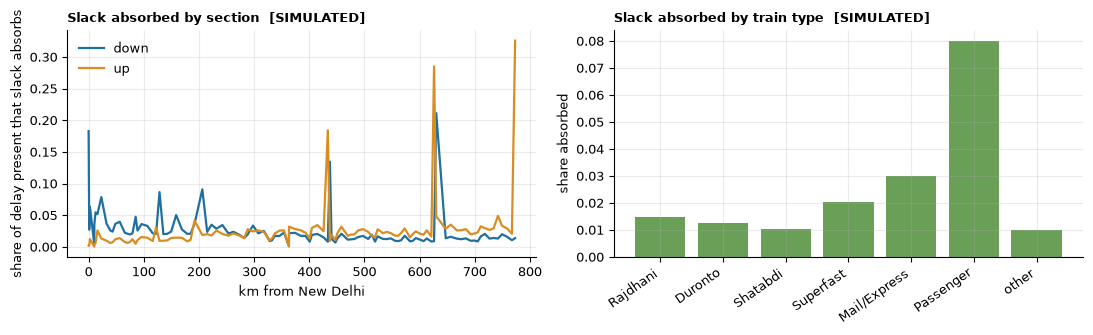

In [4]:
sa = app["slack_absorbed"]; st = app["slack_absorbed_type"].set_index("type").reindex(order)
print("share of the delay present on a section that slack absorbs: overall %.3f; by section median %.3f (range %.3f-%.3f)" % (
    sa.absorbed_min.sum() / sa.present_min.sum(), sa.share_absorbed.median(), sa.share_absorbed.min(), sa.share_absorbed.max()))
print(st[["absorbed_min", "present_min", "share_absorbed"]].round(4).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for dr, col, l in ((1, BLUE, "down"), (-1, ORANGE, "up")):
    s = sa[sa.dir == dr].sort_values("sec"); axes[0].plot(km[s.sec].values, s.share_absorbed, color=col, lw=1.6, label=l)
axes[0].set_xlabel("km from New Delhi"); axes[0].set_ylabel("share of delay present that slack absorbs"); axes[0].legend(frameon=False)
axes[0].set_title("Slack absorbed by section" + S, loc="left", fontweight="bold", fontsize=9)
axes[1].bar(range(len(order)), st.share_absorbed, color=GREEN); axes[1].set_xticks(range(len(order))); axes[1].set_xticklabels(order, rotation=35, ha="right")
axes[1].set_ylabel("share absorbed"); axes[1].set_title("Slack absorbed by train type" + S, loc="left", fontweight="bold", fontsize=9)
plt.tight_layout(); save(fig, "03_slack_absorbed")

## 3. Cascades (observable extraction)

A run's cause is the earliest of: a late feeder rake (timetable link), an external entry delay of at least 15 minutes, a primary event of its own, or a late leader that delayed it by at least 2 minutes. A run is in a cascade only if its chain of causes ends in an external or primary trigger; cascades are rooted trees of runs.

decision window (design) {'cascades': 12221, 'share_size_2plus': 0.43695278618770966, 'median_size': 1.0, 'p90_size': 5.0, 'max_size': 35, 'mean_size': 2.390311758448572, 'share_depth_2plus': 0.2363145405449636, 'max_depth': 17, 'median_duration_min': 0.0, 'primary': 4864, 'external_entry': 7357}
application window (frozen) {'cascades': 12518, 'share_size_2plus': 0.4308196197475635, 'median_size': 1.0, 'p90_size': 5.0, 'max_size': 43, 'mean_size': 2.366831762262342, 'share_depth_2plus': 0.23382329445598338, 'max_depth': 18, 'median_duration_min': 0.0, 'primary': 4861, 'external_entry': 7657}


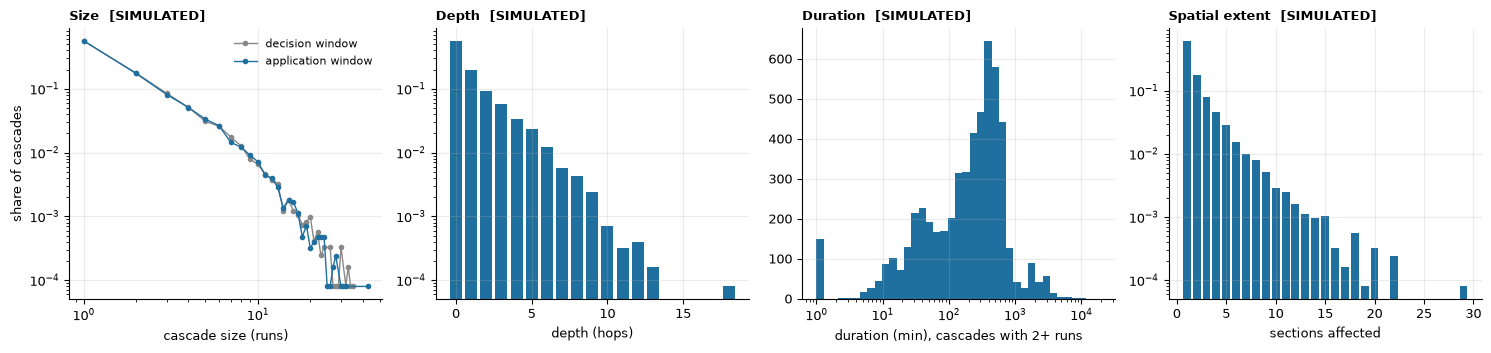


cascades started per day by the weather of the origin day: {'clear': 38.1, 'fog': 70.8, 'rain': 41.7} | mean size: {'clear': 2.37, 'fog': 2.21, 'rain': 2.62} | primary-rooted per day: {'clear': 15.6, 'fog': 18.7, 'rain': 17.0}

by season of the origin:
                      cascades  mean_size  p90  mean_depth  share_2plus  mean_extent
season                                                                              
Jan-Feb (fog season)      2990       2.29  5.0        0.95         0.42         1.93
Jun-Aug                   3660       2.42  5.0        1.02         0.43         1.99
Mar-May                   2988       2.44  5.0        1.05         0.45         1.98
Nov-Dec (fog season)      2880       2.30  5.0        0.96         0.42         1.94

by weather on the origin day:
        cascades  mean_size  p90  mean_depth  share_2plus  mean_extent
wx_day                                                                
clear       9677       2.37  5.0         1.0         0.43      

In [5]:
cd, ca = dec["cascades"], app["cascades"]
for nm, c_ in (("decision window (design)", cd), ("application window (frozen)", ca)):
    print(nm, cs.summarise(c_))
from src import splits
wx = pd.concat([pd.read_parquet(Path(s.dir) / "weather.parquet") for s in splits.sources("medium")]); wx["date"] = pd.to_datetime(wx.date)
wx = wx[(wx.date >= APP[0]) & (wx.date <= APP[1])].set_index("date").state.astype(str)
day_of = lambda t_: (pd.Timestamp("2025-01-01") + pd.to_timedelta(t_, unit="m")).dt.normalize()
ca = ca.assign(season=eda.season_of(ca.origin_month.to_numpy()), wx_day=day_of(ca.origin_time).map(wx)); ca["fog"] = ca.wx_day == "fog"
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for c_, col, l in ((cd, GREY, "decision window"), (ca, BLUE, "application window")):
    v = c_.size_runs.value_counts().sort_index(); axes[0].loglog(v.index, v.values / v.sum(), marker="o", ms=3, lw=1, color=col, label=l)
axes[0].set_xlabel("cascade size (runs)"); axes[0].set_ylabel("share of cascades"); axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("Size" + S, loc="left", fontweight="bold", fontsize=9)
d = ca.depth.value_counts().sort_index(); axes[1].bar(d.index, d.values / d.sum(), color=BLUE); axes[1].set_yscale("log"); axes[1].set_xlabel("depth (hops)"); axes[1].set_title("Depth" + S, loc="left", fontweight="bold", fontsize=9)
axes[2].hist(ca[ca.size_runs >= 2].duration_min.clip(1, 20000), bins=np.logspace(0, 4.3, 40), color=BLUE); axes[2].set_xscale("log"); axes[2].set_xlabel("duration (min), cascades with 2+ runs"); axes[2].set_title("Duration" + S, loc="left", fontweight="bold", fontsize=9)
e = ca.extent_sections.value_counts().sort_index(); axes[3].bar(e.index, e.values / e.sum(), color=BLUE); axes[3].set_yscale("log"); axes[3].set_xlabel("sections affected"); axes[3].set_title("Spatial extent" + S, loc="left", fontweight="bold", fontsize=9)
plt.tight_layout(); save(fig, "04_cascade_distributions")
by = lambda col: ca.groupby(col).agg(cascades=("size_runs", "size"), mean_size=("size_runs", "mean"), p90=("size_runs", lambda s: s.quantile(.9)), mean_depth=("depth", "mean"), share_2plus=("size_runs", lambda s: (s >= 2).mean()), mean_extent=("extent_sections", "mean")).round(2)
wdays = wx.value_counts()
print("\ncascades started per day by the weather of the origin day:", (ca.groupby("wx_day").size() / wdays).round(1).to_dict(), "| mean size:", ca.groupby("wx_day").size_runs.mean().round(2).to_dict(), "| primary-rooted per day:", (ca[ca.origin_type == "primary"].groupby("wx_day").size() / wdays).round(1).to_dict())
print("\nby season of the origin:"); print(by("season").to_string()); print("\nby weather on the origin day:"); print(by("wx_day").to_string()); print("\nby origin type:"); print(by("origin_type").to_string())

scenario                 window              varied  value  cascades  mean_size  median_size  p90_size  max_size  share_size_2plus  share_depth_2plus  max_depth  primary  external_entry
  medium 2024-11-01..2025-08-31 P and entry trigger     10     18942      1.977          1.0       4.0        28             0.372              0.179         14     7737           11205
  medium 2024-11-01..2025-08-31 P and entry trigger     15     12518      2.367          1.0       5.0        43             0.431              0.234         18     4861            7657
  medium 2024-11-01..2025-08-31 P and entry trigger     20      8136      2.626          1.0       6.0        50             0.468              0.267         21     2729            5407
  medium 2024-11-01..2025-08-31 P and entry trigger     30      4086      2.790          1.0       6.0        39             0.479              0.283         18     1144            2942
  medium 2024-11-01..2025-08-31                   G      4     13297  

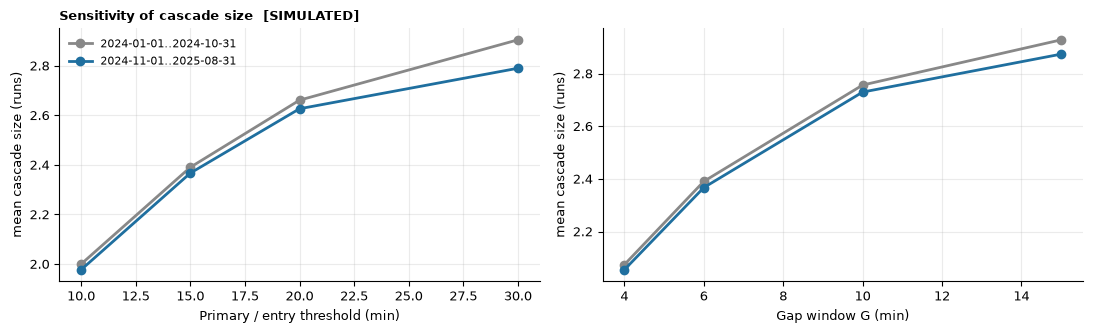

In [6]:
sens = pd.read_parquet("data/processed/mining/sensitivity.parquet")
cols = ["scenario", "window", "varied", "value", "cascades", "mean_size", "median_size", "p90_size", "max_size", "share_size_2plus", "share_depth_2plus", "max_depth", "primary", "external_entry"]
print(sens[sens.window.str.startswith("2024-11")][cols].round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for w, col in ((sens.window.unique()[0], GREY), (sens.window.unique()[1], BLUE)):
    s = sens[sens.window == w]
    for ax, v, ttl in ((axes[0], "P and entry trigger", "Primary / entry threshold (min)"), (axes[1], "G", "Gap window G (min)")):
        x = s[s.varied == v]; ax.plot(x.value, x.mean_size, marker="o", color=col, lw=2, label=w)
        ax.set_xlabel(ttl); ax.set_ylabel("mean cascade size (runs)")
axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("Sensitivity of cascade size" + S, loc="left", fontweight="bold", fontsize=9); plt.tight_layout(); save(fig, "05_sensitivity")

## 4. Critical sections and trains

top sections by how often a primary event starts a cascade there:
 section  origin_freq  primary_minutes  size_triggered  rank_origin_freq  rank_primary_minutes  rank_size_triggered  rank_pagerank_station  rank_edge_betweenness  rank_train_graph_score
 ETW-EKL          454     20134.552734             904               1.0                   1.0                  1.0                   91.0                   22.0                     5.0
CNB-CNBI          274      6391.666992             308               2.0                   3.0                  9.0                    8.0                   14.0                    29.0
 ARW-JEP          237      7254.229980             742               3.0                   2.0                  2.0                    3.0                  104.0                    98.0
 TDL-HNG          136      6270.076172             408               4.0                   4.0                  6.0                   23.0                   42.0                     1.0
PATA

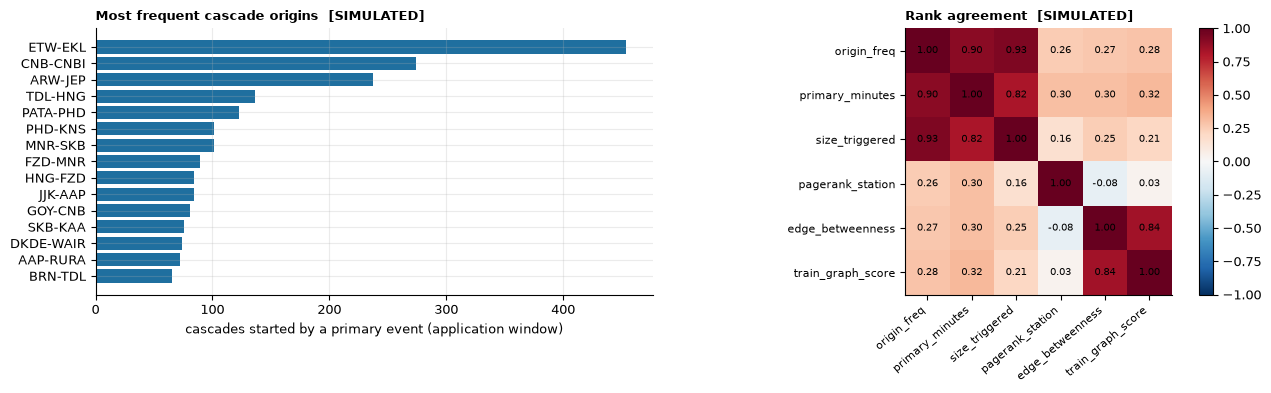


artifact flags:
   item  section               in_top_of  flagged
KNS-PJY       50 [rank_edge_betweenness]     True

top trains as leaders of delayed followers:
train                                   name         type  origin_cascades  leader_links  caused_minutes  pagerank  betweenness
13040                         Janata Express Mail/Express            165.0         745.0        5817.286     0.006        0.077
51810                Tundla Kanpur Passenger    Passenger            166.0         389.0        4878.952     0.004        0.049
22812 New Delhi-Bhubaneswar Rajdhani Express     Rajdhani             21.0         217.0        1856.137     0.005        0.009
12453      Ranchi-New Delhi Rajdhani Express     Rajdhani             11.0         213.0        2113.914     0.006        0.003
12877            Ranchi-New Delhi Garib Rath    Superfast             22.0         212.0        1815.889     0.006        0.011
03686                           Delhi Gaya S        other             

In [7]:
cs_ = app["critical_sections"].copy()
cols = ["origin_freq", "primary_minutes", "size_triggered", "pagerank_station", "edge_betweenness", "train_graph_score"]
print("top sections by how often a primary event starts a cascade there:")
print(cs_.sort_values("rank_origin_freq").head(10)[["section", "origin_freq", "primary_minutes", "size_triggered", "rank_origin_freq", "rank_primary_minutes", "rank_size_triggered", "rank_pagerank_station", "rank_edge_betweenness", "rank_train_graph_score"]].round(3).to_string(index=False))
corr = cr.rank_correlations(cs_, cols); print("\nSpearman rank correlation between the rankings (107 sections):"); print(corr.round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top = cs_.sort_values("origin_freq", ascending=False).head(15)[::-1]
axes[0].barh(top.section, top.origin_freq, color=BLUE); axes[0].set_xlabel("cascades started by a primary event (application window)"); axes[0].set_title("Most frequent cascade origins" + S, loc="left", fontweight="bold", fontsize=9)
im = axes[1].imshow(corr.values, vmin=-1, vmax=1, cmap="RdBu_r"); axes[1].set_xticks(range(len(cols))); axes[1].set_xticklabels(cols, rotation=40, ha="right", fontsize=8); axes[1].set_yticks(range(len(cols))); axes[1].set_yticklabels(cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)): axes[1].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
axes[1].grid(False); plt.colorbar(im, ax=axes[1]); axes[1].set_title("Rank agreement" + S, loc="left", fontweight="bold", fontsize=9); plt.tight_layout(); save(fig, "06_critical_sections")
print("\nartifact flags:"); print(app["artifact_flags"].to_string(index=False))
ct_ = app["critical_trains"]
print("\ntop trains as leaders of delayed followers:"); print(ct_.sort_values("rank_leader_links").head(8)[["train", "name", "type", "origin_cascades", "leader_links", "caused_minutes", "pagerank", "betweenness"]].round(3).to_string(index=False))
print("\nrank correlation between train rankings:"); print(cr.rank_correlations(ct_, ["origin_cascades", "leader_links", "caused_minutes", "pagerank", "betweenness"]).round(2).to_string())
d1, d2 = dec["critical_sections"].set_index("sec"), cs_.set_index("sec")
print("\nstability of section rankings, decision vs application window (Spearman):", {c_: round(d1[c_].corr(d2[c_], method="spearman"), 3) for c_ in ("origin_freq", "primary_minutes", "size_triggered")})

## 5. Frequent propagation patterns

Section sequences along chains of section links (rake links excluded). "Moving" patterns change section at each step (delay travelling along the line); "queue" patterns repeat the same section (a platoon of followers behind a late leader). Support = share of cascades that show the pattern; confidence = how often a chain through A->B continues to C.


moving patterns: 48 pairs and 1 triples with count >= 30
                     pattern  count  cascades  support  confidence
ARW-JEP > KCN-BEP > GHSR-ULD     48        48    0.016       0.522
           pattern  count  cascades  support
JEP-MGS > SFG-PRYG    179       178    0.033
 TDL-HNG > HNG-FZD    113       105    0.019
 JEP-MGS > GOY-CNB     93        93    0.017
 ARW-JEP > KCN-BEP     92        92    0.017
 GOY-CNB > TDL-HNG     87        87    0.016
 TDL-HNG > FZD-MNR     79        79    0.015



same-section (queue) patterns: 44 pairs and 6 triples with count >= 30
                          pattern  count  cascades  support  confidence
   RURA-RMW > RURA-RMW > RURA-RMW    134       104    0.036       0.480
      TDL-HNG > TDL-HNG > TDL-HNG    113        82    0.028       0.274
   GHSR-ULD > GHSR-ULD > GHSR-ULD     82        52    0.018       0.466
      HNG-FZD > HNG-FZD > HNG-FZD     37        27    0.009       0.207
DKDE-WAIR > DKDE-WAIR > DKDE-WAIR     30        29    0.010       0.323
            pattern  count  cascades  support
  TDL-HNG > TDL-HNG    413       297    0.055
RURA-RMW > RURA-RMW    279       145    0.027
  JEP-MGS > JEP-MGS    214       194    0.036
  HNG-FZD > HNG-FZD    179       140    0.026
GHSR-ULD > GHSR-ULD    176        94    0.017
  GOY-CNB > GOY-CNB    120       100    0.019

transitions between physical segments (rows: from, columns: to); share staying inside a segment: 0.603
          NDLS-TDL  TDL-ETW  ETW-CNB  CNB-PRYG  PRYG-MGS
NDLS-TDL     


length 2: moving patterns at least twice as common in Jan-Feb (fog season) than elsewhere (count >= 15): 1
          pattern  count  support  support_other  lift
GOY-CNB > PJY-JJK     18    0.014          0.005 2.803

length 2: moving patterns at least twice as common in Nov-Dec (fog season) than elsewhere (count >= 15): 1
          pattern  count  support  support_other  lift
JEP-MGS > BDL-MZP     15    0.012          0.005 2.252



length 3: moving patterns at least twice as common in Jan-Feb (fog season) than elsewhere (count >= 15): 0

length 3: moving patterns at least twice as common in Nov-Dec (fog season) than elsewhere (count >= 15): 0


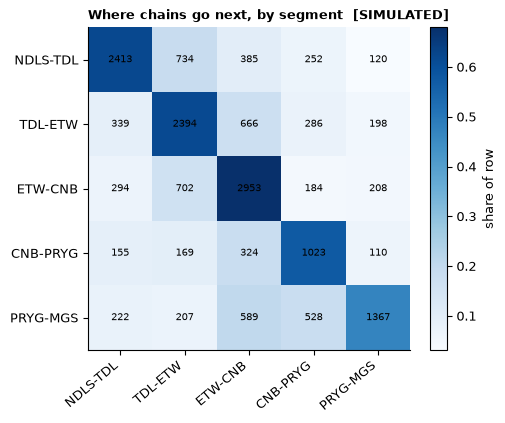

In [8]:
m, c_ = app["members"], app["cascades"]
anch = [names.index(n) for n in ["NDLS", "TDL", "ETW", "CNB", "PRYG", "MGS"]]
lb = lambda *xs: " > ".join(lab(x) for x in xs)
for mv, title in ((True, "moving patterns"), (False, "same-section (queue) patterns")):
    p2, p3 = pt.frequent_patterns(m, c_, min_count=30, moving=mv)
    print(f"\n{title}: {len(p2)} pairs and {len(p3)} triples with count >= 30")
    if len(p3):
        p3["pattern"] = [lb(a, b, x) for a, b, x in zip(p3.a, p3.b, p3.c)]; print(p3.head(5)[["pattern", "count", "cascades", "support", "confidence"]].round(3).to_string(index=False))
    p2["pattern"] = [lb(a, b) for a, b in zip(p2.a, p2.b)]; print(p2.head(6)[["pattern", "count", "cascades", "support"]].round(3).to_string(index=False))
mat, stay = pt.segment_transitions(m, anch)
seg_names = ["NDLS-TDL", "TDL-ETW", "ETW-CNB", "CNB-PRYG", "PRYG-MGS"]
print("\ntransitions between physical segments (rows: from, columns: to); share staying inside a segment: %.3f" % stay)
print(pd.DataFrame(mat, index=seg_names, columns=seg_names).to_string())
c_ = c_.assign(season=eda.season_of(c_.origin_month.to_numpy()))
for length in (2, 3):
    sup = pt.pattern_support_by_group(m, c_, c_.season.to_numpy(), length=length)
    for grp in (eda.FOG_SEASON, "Nov-Dec (fog season)"):
        fg = pt.group_specific(sup, grp, min_count=15)
        fg = fg[(fg.a != fg.b)]
        print(f"\nlength {length}: moving patterns at least twice as common in {grp} than elsewhere (count >= 15): {len(fg)}")
        if len(fg): print(fg.head(4).assign(pattern=lambda d: [lb(*r) for r in d[[x for x in ('a', 'b', 'c') if x in d]].itertuples(index=False)])[["pattern", "count", "support", "support_other", "lift"]].round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(mat / mat.sum(axis=1, keepdims=True), cmap="Blues"); ax.set_xticks(range(5)); ax.set_xticklabels(seg_names, rotation=40, ha="right"); ax.set_yticks(range(5)); ax.set_yticklabels(seg_names)
for i in range(5):
    for j in range(5): ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=7, color="black")
ax.grid(False); ax.set_title("Where chains go next, by segment" + S, loc="left", fontweight="bold", fontsize=9); plt.colorbar(im, label="share of row"); save(fig, "07_segment_transitions")

## 6. Station communities

Nodes are clustered by the correlation of their hourly (deseasoned) delay series with average linkage. The number of clusters was chosen on the decision window by silhouette score, **without looking at the physical segments**, and frozen. The silhouette rises all the way to the end of the search range (k = 10), so there is no natural cluster count; the cluster number is the cap of the range. For reference a k = 5 clustering (the number of physical segments) and a Louvain modularity clustering are also shown.

frozen: {'k': 10, 'linkage': 'average', 'deseason': True, 'louvain_tau': 0.5} | silhouette by k on the decision window: {2: 0.1858, 3: 0.2692, 4: 0.3149, 5: 0.3319, 6: 0.3535, 7: 0.3628, 8: 0.3784, 9: 0.4007, 10: 0.4137}


                                             0                   1                          2
window                         decision window  application window  application window, k = 5
hier_clusters                               10                  10                          5
hier_ARI                                 0.505               0.473                       0.68
hier_NMI                                 0.727               0.696                       0.75
hier_blocks_along_chain                     10                  10                          5
hier_adjacent_same_cluster               0.916               0.916                      0.963
louvain_clusters                             6                   5                          5
louvain_ARI                              0.643               0.694                      0.694
louvain_NMI                              0.761                0.76                       0.76
louvain_blocks_along_chain                   6              

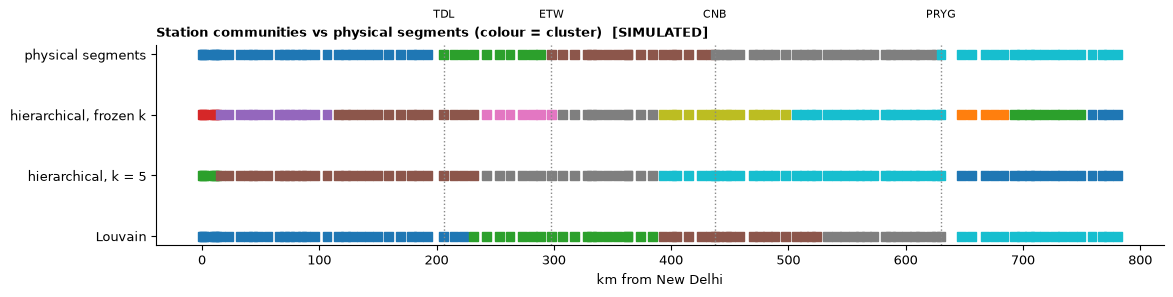

k = 5 cluster boundaries at stations: ['SBB', 'SKB', 'RURA', 'KCN'] | physical segment boundaries: TDL, ETW, CNB, PRYG


In [9]:
fz = cm.load_frozen_communities(); print("frozen:", {k: v for k, v in fz.items() if k != "silhouette"}, "| silhouette by k on the decision window:", fz["silhouette"])
res = {}
for nm, (a, b), k in (("decision window", DEC, None), ("application window", APP, None), ("application window, k = 5", APP, 5)):
    res[nm] = cm.communities_for_window(Path(mp.OUT) / "medium" / f"{a}_{b}" / "hourly.npz", names, k=k)
rows = [{"window": nm, **{f"hier_{k}": v for k, v in r["hierarchical"].items()}, **{f"louvain_{k}": v for k, v in r["louvain_cmp"].items()}} for nm, r in res.items()]
print(pd.DataFrame(rows).round(3).T.to_string())
seg = res["application window"]["segments"]
fig, ax = plt.subplots(figsize=(13, 2.6))
rowsplot = [("physical segments", seg), ("hierarchical, frozen k", res["application window"]["labels"]), ("hierarchical, k = 5", res["application window, k = 5"]["labels"]), ("Louvain", res["application window"]["louvain"])]
for i, (n_, labels) in enumerate(rowsplot):
    ax.scatter(km.values, np.full(len(labels), len(rowsplot) - i), c=labels, cmap="tab10", s=40, marker="s")
ax.set_yticks(range(1, len(rowsplot) + 1)); ax.set_yticklabels([r[0] for r in rowsplot][::-1]); ax.set_xlabel("km from New Delhi")
for nme in ["TDL", "ETW", "CNB", "PRYG"]: ax.axvline(km[names.index(nme)], color=GREY, ls=":", lw=1); ax.text(km[names.index(nme)], len(rowsplot) + 0.6, nme, ha="center", fontsize=8)
ax.set_title("Station communities vs physical segments (colour = cluster)" + S, loc="left", fontweight="bold", fontsize=9); ax.grid(False); save(fig, "08_communities")
lab5 = res["application window, k = 5"]["labels"]; bnd = [names[i] for i in range(1, len(lab5)) if lab5[i] != lab5[i - 1]]
print("k = 5 cluster boundaries at stations:", bnd, "| physical segment boundaries: TDL, ETW, CNB, PRYG")

## One cascade on the map

cascade 6975: origin MIU-DER by train 13040 at 2025-08-24 16:58:44.216308596 (primary event, 19 min added); 43 runs, depth 18, 2324 min, 29 sections, 336 delay-minutes


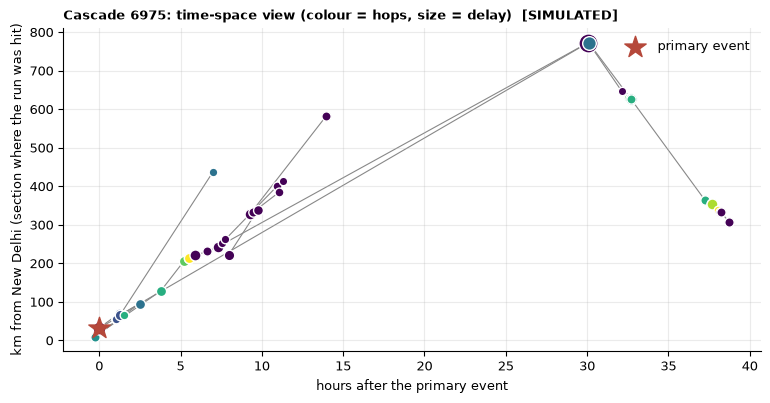

In [10]:
import folium
mem, casc, links = app["members"], app["cascades"], app["links"]
cand = casc[(casc.origin_type == "primary") & (casc.size_runs >= 12) & (casc.depth >= 4)].sort_values("extent_sections", ascending=False)
cas = cand.iloc[0]; cid = int(cas.cascade_id)
mm = mem[mem.cascade_id == cid].sort_values("cause_time")
t0 = float(cas.origin_time); epoch = pd.Timestamp("2025-01-01")
print(f"cascade {cid}: origin {lab(int(cas.origin_sec))} by train {cas.origin_train} at {epoch + pd.to_timedelta(t0, unit='m')} (primary event, {cas.origin_amount:.0f} min added); "
      f"{int(cas.size_runs)} runs, depth {int(cas.depth)}, {cas.duration_min:.0f} min, {int(cas.extent_sections)} sections, {cas.total_delay_min:.0f} delay-minutes")
fig, ax = plt.subplots(figsize=(9, 4.2))
cmap = plt.cm.viridis
for r in mm.itertuples():
    y = km[int(r.cause_sec)] if r.cause_sec >= 0 else np.nan
    ax.scatter((r.cause_time - t0) / 60, y, s=30 + 3 * r.amount, color=cmap(min(r.depth / 8, 1)), edgecolor="white", zorder=3)
    if r.parent >= 0 and r.parent in set(mm.run_idx):
        p_ = mm[mm.run_idx == r.parent].iloc[0]
        ax.plot([(p_.cause_time - t0) / 60, (r.cause_time - t0) / 60], [km[int(p_.cause_sec)], y], color=GREY, lw=0.8, zorder=1)
ax.scatter([0], [km[int(cas.origin_sec)]], marker="*", s=260, color=RED, zorder=4, label="primary event")
ax.set_xlabel("hours after the primary event"); ax.set_ylabel("km from New Delhi (section where the run was hit)"); ax.legend(frameon=False)
ax.set_title(f"Cascade {cid}: time-space view (colour = hops, size = delay)" + S, loc="left", fontweight="bold", fontsize=9); save(fig, "09_cascade_time_space")
nd = nodes.set_index("node"); mp_ = folium.Map(location=[nd.lat.mean(), nd.lon.mean()], zoom_start=6, tiles="OpenStreetMap")
for s in range(len(nd) - 1): folium.PolyLine([(nd.lat[s], nd.lon[s]), (nd.lat[s + 1], nd.lon[s + 1])], color="#bbbbbb", weight=2).add_to(mp_)
for sec, g in mm.groupby("cause_sec"):
    if sec < 0: continue
    s = int(sec); a, b = nd.loc[s], nd.loc[s + 1]; is_origin = s == int(cas.origin_sec)
    folium.PolyLine([(a.lat, a.lon), (b.lat, b.lon)], color=RED if is_origin else ORANGE, weight=8 if is_origin else 3 + min(len(g), 8),
                    tooltip=f"{lab(s)}: {len(g)} runs hit, first at hop {int(g.depth.min())} [SIMULATED]").add_to(mp_)
Path("reports/figures").mkdir(exist_ok=True); mp_.save("reports/figures/mining_09_cascade_map_SIMULATED.html"); mp_

## Where the numbers go next

`reports/phase5_findings.md` states the numbered findings with the artifact assessment. `07_mining_validation.ipynb` compares the inferred cascades and links with the ground truth (this is the first and only place the ground truth is read); the frozen pipeline is also run unchanged on the low and high scenarios there.